In [1]:
import pandas as pd 
from datetime import datetime, timedelta
import matplotlib.pyplot as plt
import yfinance as yf
import numpy as np
from scipy.optimize import minimize


In [9]:
tickers = ['SPY', 'BND',  'GLD', 'QQQ', 'VTI']

In [ ]:
end_date = datetime.today()
start_date = end_date - timedelta(days=365*5)
print(start_date)


2020-07-15 13:07:30.612058


In [4]:
adj_close_df = pd.DataFrame()

In [13]:
for ticker in tickers:
    data = yf.download(ticker, start=start_date, end=end_date,  auto_adjust=False)
    adj_close_df[ticker] = data['Adj Close']
 
   

[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed


In [14]:
print(adj_close_df.head())

                   SPY        BND         GLD         QQQ         VTI
Date                                                                 
2020-07-15  299.680328  76.761803  170.339996  253.345520  151.797516
2020-07-16  298.693420  76.813766  168.729996  251.617111  151.118958
2020-07-17  299.559357  76.891617  170.119995  251.908417  151.695236
2020-07-20  301.980255  76.969482  170.940002  259.055298  152.857178
2020-07-21  302.622742  77.012825  173.000000  256.355865  153.294113


In [27]:
# Calculate log returns
log_returns = np.log(adj_close_df/adj_close_df.shift(1)).dropna()



In [18]:
#Calculate covariance matrix
cov_matrix = log_returns.cov()*252
print(cov_matrix)

          SPY       BND       GLD       QQQ       VTI
SPY  0.030673  0.001946  0.003787  0.038481  0.031149
BND  0.001946  0.003572  0.003104  0.002788  0.002036
GLD  0.003787  0.003104  0.023882  0.005051  0.003945
QQQ  0.038481  0.002788  0.005051  0.054890  0.039152
VTI  0.031149  0.002036  0.003945  0.039152  0.031967


In [19]:
#Calculate Portfolio Standard Deviation
def portfolio_std(weights, cov_matrix):
    variance = weights.T @ cov_matrix @ weights
    return np.sqrt(variance)

In [23]:
#Calculate expected returns
def expected_returns(weights, log_returns):
    return np.sum(log_returns.mean()*weights)*252

In [24]:
#Calculate Sharpe Ratio
def sharpe_ratio(weights, log_returns, cov_matrix, risk_free_rate):
    return (expected_returns(weights, log_returns)-risk_free_rate)/portfolio_std(weights, cov_matrix)

In [ ]:
# Set Risk-free rate
from fredapi import Fred
fred = Fred(api_key = '3c4ec30e618f1bd60016581d6e1565a1')
ten_yr_tr_rate = fred.get_series('GS10')/100

risk_free_rate = ten_yr_tr_rate.iloc[-1] #latest value
print(risk_free_rate)

0.0438


Defining the function to minimize(negative sharpe ratio): In the case of the scipy.optimize.minimze() function, there is no direct method to find the maximum value of a function

In [32]:
def negative_sharpe_ratio(weights, log_returns, cov_matrix, risk_free_rate):
    return -sharpe_ratio(weights, log_returns, cov_matrix, risk_free_rate)

In [48]:
#Set constraints and bounds
constraints= {'type':'eq','fun': lambda weights: np.sum(weights)-1}
bounds = [(0, 0.5) for _ in range(len(tickers))]

In [35]:
initial_weights = np.array([1/len(tickers)]*len(tickers))
print(initial_weights)

[0.2 0.2 0.2 0.2 0.2]


In [49]:
#Optimize weights to maximize Sharpe Ratio. SLSQP method stands for Sequential Least Squares Quadratic Programming, suitable for solving non-linear optimization problems with constraints.
results = minimize(negative_sharpe_ratio, initial_weights, args=(log_returns, cov_matrix, risk_free_rate), method='SLSQP', constraints=constraints, bounds=bounds)

In [50]:
optimal_weights = results.x

In [59]:
print('Optimal Weights:')
for ticker, weights in zip(tickers, optimal_weights):
    print(f"{ticker}: {weights:.4f}")
    
print()

optimal_portfolio_std = portfolio_std(optimal_weights, cov_matrix)
optimal_portfolio_returns = expected_returns(optimal_weights, log_returns)
optimal_sharpe_ratio = sharpe_ratio(optimal_weights, log_returns, cov_matrix, risk_free_rate)

print(f"Expected Annual Return: {optimal_portfolio_std:.4f}")
print(f"Expected Volatility: {optimal_portfolio_std:.4f}")
print(f"Sharpe Ratio: {optimal_sharpe_ratio:.4f}")

Optimal Weights:
SPY: 0.5000
BND: 0.0000
GLD: 0.4991
QQQ: 0.0000
VTI: 0.0009

Expected Annual Return: 0.1247
Expected Volatility: 0.1247
Sharpe Ratio: 0.7207


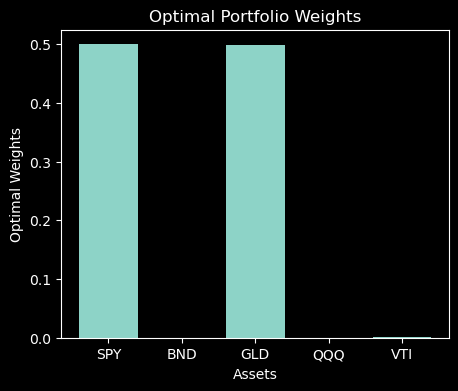

In [63]:
plt.figure(figsize=(5, 4))
plt.bar(tickers, optimal_weights)
plt.xlabel('Assets')
plt.ylabel('Optimal Weights')
plt.title('Optimal Portfolio Weights')
plt.show()